In [1]:
import pandas as pd
from pathlib import Path

DATA = Path("data/nut_special")
manifest = pd.read_csv(DATA / "manifest.csv")
manifest[["file", "split", "label", "face", "light", "raw_centroid_x", "raw_centroid_y"]].head()

,file,split,label,face,light,raw_centroid_x,raw_centroid_y
0,frames/A_under/train/train_A_under_f001.bmp,train,normal,A,under,1011.75,1340.43
1,frames/A_under/train/train_A_under_f002.bmp,train,normal,A,under,982.52,1343.81
2,frames/A_under/train/train_A_under_f003.bmp,train,normal,A,under,1032.13,1344.69
3,frames/A_under/train/train_A_under_f004.bmp,train,normal,A,under,1041.20,1347.79
4,frames/A_under/train/train_A_under_f005.bmp,train,normal,A,under,989.99,1338.50


In [2]:
is_view = (manifest["face"] == "A") & (manifest["light"] == "under")
is_defect = manifest["split"] == "defects"
row = manifest[is_view & is_defect].iloc[0]
row

file                                frames/A_under/defects/p077_A_under.bmp
capture_id                                                     p077_A_under
part_id                                                                p077
part_identity_status                              tray_order_user_confirmed
tray_index                                                              1.0
split                                                               defects
label                                                                defect
defect_class                                                            NaN
face                                                                      A
light                                                                 under
raw_name                                    Image__2026-10-10__21-15-20.bmp
raw_path                  defects/light_under/Image__2026-10-10__21-15-2...
capture_time                                            2026-10-10T21:15:20
sha256      

In [3]:
SIZE = 700
W, H = 2592, 1944

def centred_box(row, size=SIZE):
    left = round(row["raw_centroid_x"]) - size // 2
    top = round(row["raw_centroid_y"]) - size // 2
    box = (left, top, left + size, top + size)
    if left < 0 or top < 0 or box[2] > W or box[3] > H:
        raise ValueError(f"box {box} leaves the photo: {row['file']}")
    return box

centred_box(row)

(774, 976, 1474, 1676)

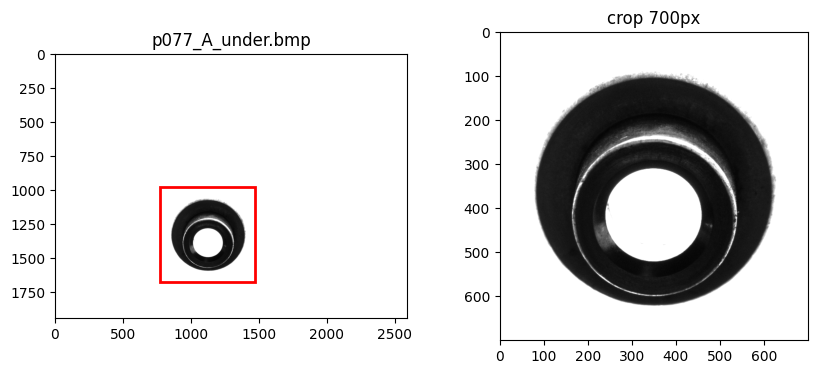

In [4]:
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

def show_crop(row, size=SIZE):
    im = Image.open(DATA / row["file"])
    box = centred_box(row, size)
    fig, (ax_full, ax_crop) = plt.subplots(1, 2, figsize=(10, 4))
    ax_full.imshow(im, cmap="gray")
    ax_full.add_patch(Rectangle(box[:2], size, size, fill=False, color="red", linewidth=2))
    ax_full.set_title(row["file"].split("/")[-1])
    ax_crop.imshow(im.crop(box), cmap="gray")
    ax_crop.set_title(f"crop {size}px")
    plt.show()

show_crop(row)

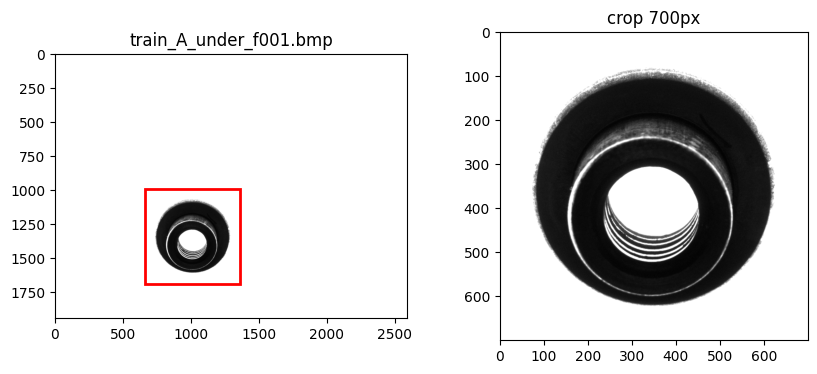

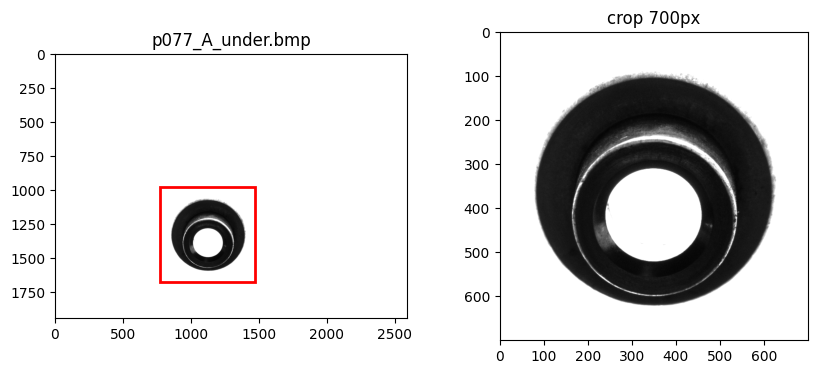

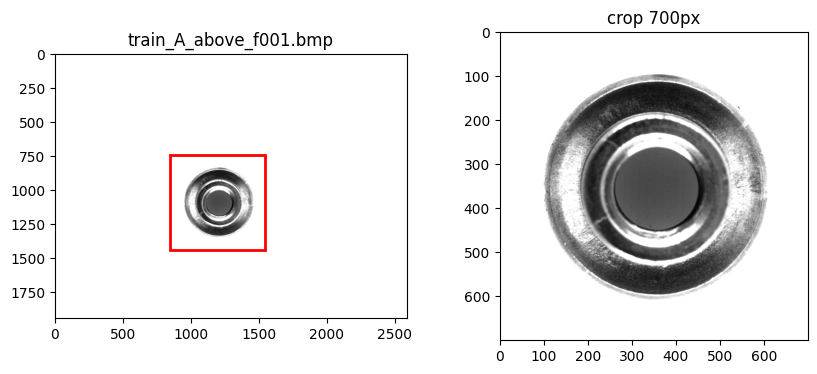

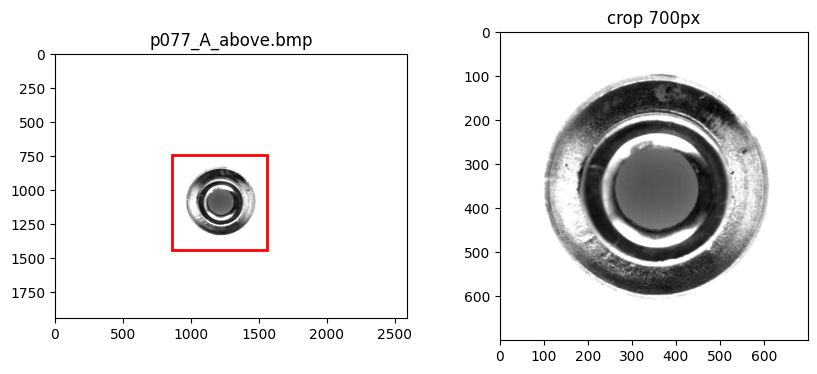

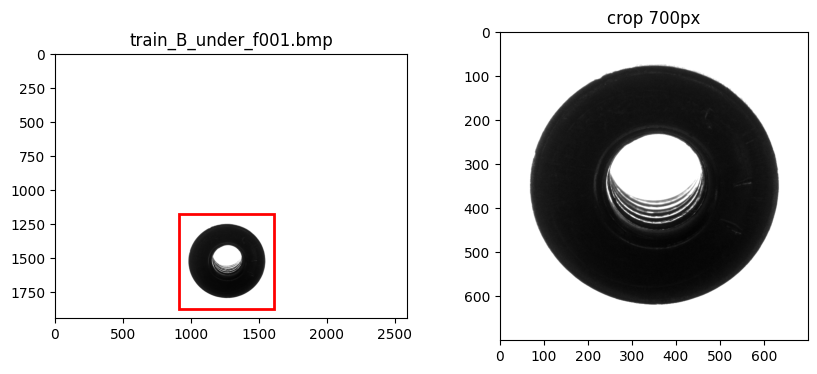

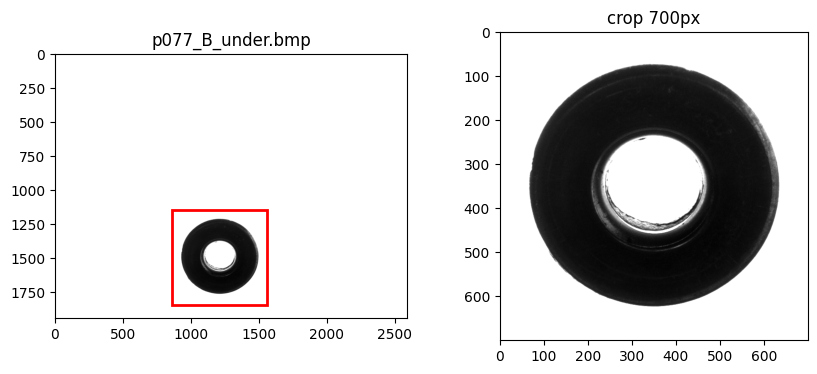

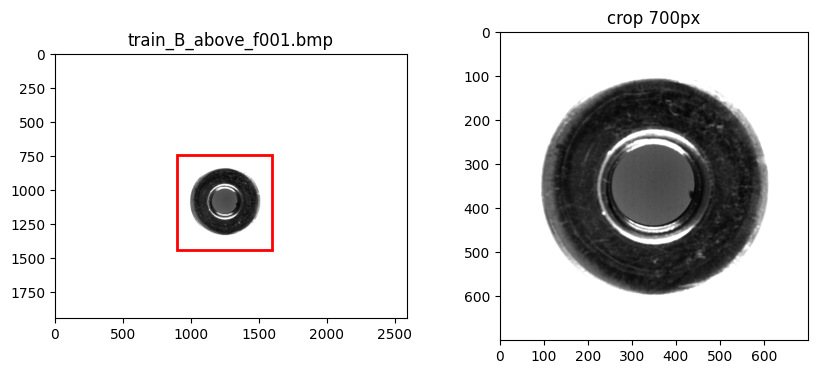

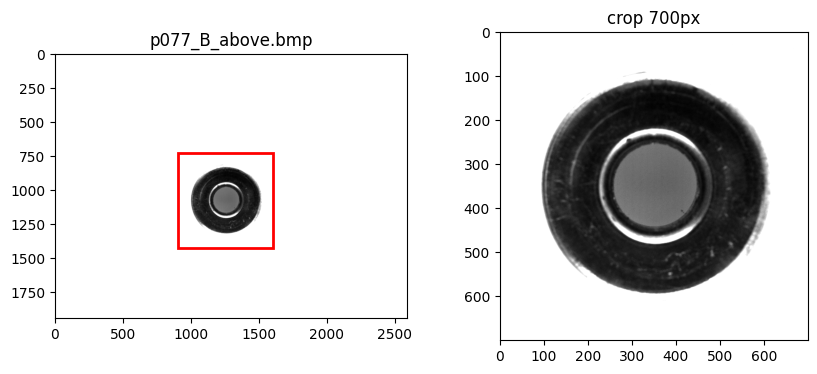

In [5]:
for face in ["A", "B"]:
    for light in ["under", "above"]:
        for split in ["train", "defects"]:
            mask = (manifest["face"] == face) & (manifest["light"] == light) & (manifest["split"] == split)
            show_crop(manifest[mask].iloc[0])

411 frames/B_under/heldout/p061_B_under.bmp (1000, 1233, 1700, 1933)


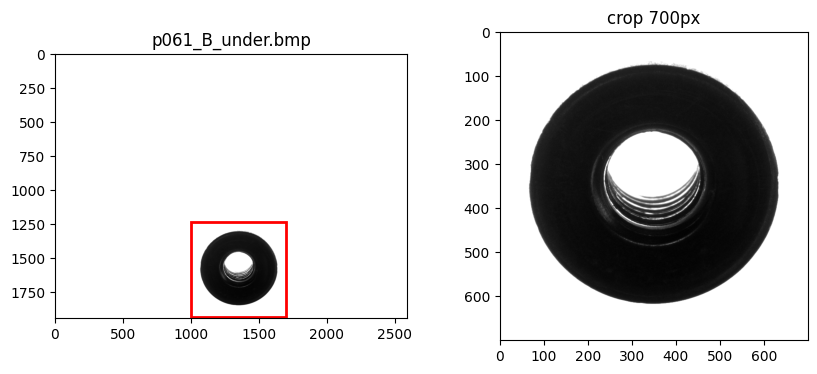

In [9]:
manifest["box"] = manifest.apply(centred_box, axis=1)
lowest = manifest.loc[manifest["box"].str[3].idxmax()]
print(len(manifest), lowest["file"], lowest["box"])
show_crop(lowest)

In [10]:
manifest["roi_file"] = manifest["file"].str.replace("frames/", "roi/", n=1).str.replace(".bmp", ".png")

for _, r in manifest.iterrows():
    out = DATA / r["roi_file"]
    out.parent.mkdir(parents=True, exist_ok=True)
    Image.open(DATA / r["file"]).crop(r["box"]).save(out)

len(list((DATA / "roi").rglob("*.png")))

411

In [11]:
manifest[["box_left", "box_top", "box_right", "box_bottom"]] = manifest["box"].tolist()
manifest.drop(columns="box").to_csv(DATA / "manifest.csv", index=False)
pd.read_csv(DATA / "manifest.csv")[["roi_file", "box_left", "box_top", "box_right", "box_bottom"]].head(3)

,roi_file,box_left,box_top,box_right,box_bottom
0,roi/A_under/train/train_A_under_f001.png,662,990,1362,1690
1,roi/A_under/train/train_A_under_f002.png,633,994,1333,1694
2,roi/A_under/train/train_A_under_f003.png,682,995,1382,1695


In [12]:
import shutil

shutil.rmtree(DATA / "frames")
for name in ["DATASET_HANDOFF.md", "dataset_schema.json", "excluded_frames.csv",
             "integrity_report.json", "organization_report.json", "part_index.csv"]:
    (DATA / name).unlink()

sorted(p.name for p in DATA.iterdir())

['manifest.csv', 'roi']

In [2]:
import random
from datetime import datetime
import torch
from torchvision.transforms import v2
from anomalib import TaskType
from anomalib.data import Folder, PredictDataset
from anomalib.engine import Engine
from anomalib.models import Patchcore

VIEWS = ["A_under", "A_above", "B_under", "B_above"]
IMAGE_SIZE = (256, 256)
SEED = 0

{v: len(list((DATA / "roi" / v / "train").glob("*.png"))) for v in VIEWS}

{'A_under': 53, 'A_above': 51, 'B_under': 51, 'B_above': 53}

In [3]:
TRANSFORM = v2.Compose([
    v2.Resize(IMAGE_SIZE, antialias=True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

EXPERIMENTS = {"joint": VIEWS} | {v: [v] for v in VIEWS}
RUN_DIR = Path("results/nut_patchcore") / datetime.now().strftime("%Y%m%d_%H%M%S")
RUN_DIR.mkdir(parents=True, exist_ok=True)

EXPERIMENTS, RUN_DIR

({'joint': ['A_under', 'A_above', 'B_under', 'B_above'],
  'A_under': ['A_under'],
  'A_above': ['A_above'],
  'B_under': ['B_under'],
  'B_above': ['B_above']},
 WindowsPath('results/nut_patchcore/20261017_153400'))

In [4]:
def make_datamodule(name, views):
    return Folder(
        name=name,
        normal_dir=[DATA / "roi" / v / "train" for v in views],
        task=TaskType.CLASSIFICATION,
        train_batch_size=8,
        eval_batch_size=8,
        num_workers=0,
        image_size=IMAGE_SIZE,
        transform=TRANSFORM,
        test_split_mode="none",
        val_split_mode="none",
    )

dm = make_datamodule("joint", EXPERIMENTS["joint"])
dm.setup()
len(dm.train_data)

208

In [5]:
def fit(name, views):
    random.seed(SEED)
    torch.manual_seed(SEED)
    model = Patchcore(backbone="resnet18", layers=["layer2", "layer3"], coreset_sampling_ratio=0.02)
    engine = Engine(
        max_epochs=1,
        accelerator="auto",
        normalization="none",
        default_root_dir=str(RUN_DIR / name),
        logger=False,
        limit_val_batches=0,
        enable_progress_bar=False,
        enable_model_summary=False,
    )
    engine.fit(model=model, datamodule=make_datamodule(name, views))
    return model, engine

model, engine = fit("joint", EXPERIMENTS["joint"])
next((RUN_DIR / "joint").rglob("*.ckpt"))

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
You are using a CUDA device ('NVIDIA GeForce RTX 3080') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
F1Score class exists for backwards compatibility. It will be removed in v1.1. Please use BinaryF1Score from torchmetrics instead
F1Score class exists for backwards compatibility. It will be removed in v1.1. Please use BinaryF1Score from torchmetrics instead
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
c:\miniconda3\envs\aio\Lib

WindowsPath('results/nut_patchcore/20261017_153400/joint/Patchcore/joint/v0/weights/lightning/model.ckpt')

In [6]:
runs = {"joint": (model, engine)}
for name, views in EXPERIMENTS.items():
    if name not in runs:
        runs[name] = fit(name, views)

sizes = {}
for name in runs:
    ckpt = next((RUN_DIR / name).rglob("*.ckpt"))
    sizes[name] = ckpt.stat().st_size // 1_000_000
sizes

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
F1Score class exists for backwards compatibility. It will be removed in v1.1. Please use BinaryF1Score from torchmetrics instead
F1Score class exists for backwards compatibility. It will be removed in v1.1. Please use BinaryF1Score from torchmetrics instead
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
c:\miniconda3\envs\aio\Lib\site-packages\lightning\pytorch\core\optimizer.py:183: `LightningModule.configure_optimizers` returned `None`, this fit will run with no optimizer
c:\miniconda3\envs\aio\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `

{'joint': 17, 'A_under': 12, 'A_above': 12, 'B_under': 12, 'B_above': 12}

In [7]:
from torch.utils.data import DataLoader

def score(name, view, split):
    model, engine = runs[name]
    dataset = PredictDataset(path=DATA / "roi" / view / split, transform=TRANSFORM, image_size=IMAGE_SIZE)
    batches = engine.predict(model=model, dataloaders=DataLoader(dataset, batch_size=8, num_workers=0))
    rows = []
    for batch in batches:
        for path, s in zip(batch["image_path"], batch["pred_scores"]):
            rows.append({"name": Path(path).name, "score": float(s)})
    return pd.DataFrame(rows)

score("joint", "A_under", "heldout").head()

ckpt_path is not provided. Model weights will not be loaded.
F1Score class exists for backwards compatibility. It will be removed in v1.1. Please use BinaryF1Score from torchmetrics instead
F1Score class exists for backwards compatibility. It will be removed in v1.1. Please use BinaryF1Score from torchmetrics instead
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
c:\miniconda3\envs\aio\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=31` in the `DataLoader` to improve performance.


,name,score
0,p053_A_under.png,8.724390
1,p054_A_under.png,8.741140
2,p055_A_under.png,9.435234
3,p056_A_under.png,8.666599
4,p057_A_under.png,8.708300


In [8]:
eval_rows = manifest["split"].isin(["heldout", "defects"])
parts = manifest[eval_rows].drop_duplicates("part_id")[["part_id", "split"]]
test_parts = parts.groupby("split").sample(frac=0.5, random_state=SEED)["part_id"]

manifest["eval_split"] = None
manifest.loc[eval_rows, "eval_split"] = "val"
manifest.loc[manifest["part_id"].isin(test_parts), "eval_split"] = "test"
manifest.to_csv(DATA / "manifest.csv", index=False)

manifest[eval_rows].drop_duplicates("part_id").groupby(["split", "eval_split"]).size()

split    eval_split
defects  test          12
         val           13
heldout  test          12
         val           12
dtype: int64

In [9]:
info = manifest.assign(name=manifest["roi_file"].str.split("/").str[-1])[["name", "part_id", "label", "eval_split"]]

frames = []
for name, views in EXPERIMENTS.items():
    for view in views:
        for split in ["heldout", "defects"]:
            df = score(name, view, split)
            df["experiment"], df["view"] = name, view
            frames.append(df)

scores = pd.concat(frames, ignore_index=True).merge(info, on="name")
val = scores[scores["eval_split"] == "val"]
val.to_csv(RUN_DIR / "val_scores.csv", index=False)
val.groupby(["experiment", "view", "label"]).size()

ckpt_path is not provided. Model weights will not be loaded.
F1Score class exists for backwards compatibility. It will be removed in v1.1. Please use BinaryF1Score from torchmetrics instead
F1Score class exists for backwards compatibility. It will be removed in v1.1. Please use BinaryF1Score from torchmetrics instead
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
c:\miniconda3\envs\aio\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=31` in the `DataLoader` to improve performance.
ckpt_path is not provided. Model weights will not be loaded.
F1Score class exists for backwards compatibility. It will be removed in v1.1. Please use BinaryF1Score from torchmetrics instead
F1Score class exists for backwards compatibility. It will be removed in v1.1. Please use BinaryF1Score from torchmetrics instead
LOCAL_RANK: 0 -

experiment  view     label 
A_above     A_above  defect    13
                     normal    12
A_under     A_under  defect    13
                     normal    12
B_above     B_above  defect    12
                     normal    12
B_under     B_under  defect    13
                     normal    12
joint       A_above  defect    13
                     normal    12
            A_under  defect    13
                     normal    12
            B_above  defect    12
                     normal    12
            B_under  defect    13
                     normal    12
dtype: int64

In [10]:
from sklearn.metrics import roc_auc_score

def compare(g):
    normal = g.loc[g["label"] == "normal", "score"]
    defect = g.loc[g["label"] == "defect", "score"]
    return pd.Series({
        "auroc": roc_auc_score(g["label"] == "defect", g["score"]),
        "caught_at_0fp": int((defect > normal.max()).sum()),
        "n_defect": len(defect),
    })

val = val.assign(setup=val["experiment"].where(val["experiment"] == "joint", "per_view"))
val.groupby(["view", "setup"]).apply(compare, include_groups=False).unstack("setup")

auroc          caught_at_0fp          n_defect         
setup       joint per_view         joint per_view    joint per_view
view                                                               
A_above  1.000000    1.000          13.0     13.0     13.0     13.0
A_under  1.000000    1.000          13.0     13.0     13.0     13.0
B_above  0.840278    0.875           5.0      6.0     12.0     12.0
B_under  1.000000    1.000          13.0     13.0     13.0     13.0

In [11]:
joint = val[val["experiment"] == "joint"]
top = joint.loc[joint.groupby("part_id")["score"].idxmax(), ["part_id", "label", "score", "view"]]
normal_max = top.loc[top["label"] == "normal", "score"].max()

print("part AUROC:", roc_auc_score(top["label"] == "defect", top["score"]))
print("caught at 0 FP:", (top.loc[top["label"] == "defect", "score"] > normal_max).sum(), "/", (top["label"] == "defect").sum())
top.sort_values("score")

part AUROC: 1.0
caught at 0 FP: 13 / 13


,part_id,label,score,view
23,p076,normal,9.222173,A_under
64,p068,normal,9.557561,A_above
155,p061,normal,9.687458,B_above
52,p056,normal,9.980106,A_above
65,p069,normal,10.029003,A_above
164,p070,normal,10.098542,B_above
147,p053,normal,10.322500,B_above
152,p058,normal,11.027488,B_above
118,p073,normal,11.157216,B_under
166,p072,normal,11.794750,B_above


In [12]:
MAX_VAL_FP = 0
normal_scores = top.loc[top["label"] == "normal", "score"]
defect_scores = top.loc[top["label"] == "defect", "score"]
candidates = sorted(top["score"])
THRESHOLD = min(t for t in candidates if (normal_scores > t).sum() <= MAX_VAL_FP)

print(f"threshold {THRESHOLD:.2f}")
print(f"val false positives {(normal_scores > THRESHOLD).sum()} / {len(normal_scores)}")
print(f"val defects caught {(defect_scores > THRESHOLD).sum()} / {len(defect_scores)}")

threshold 13.07
val false positives 0 / 12
val defects caught 13 / 13


In [13]:
test = scores[(scores["eval_split"] == "test") & (scores["experiment"] == "joint")]
test_top = test.loc[test.groupby("part_id")["score"].idxmax(), ["part_id", "label", "score", "view"]]
test_top["flagged"] = test_top["score"] > THRESHOLD
test_top.to_csv(RUN_DIR / "test_parts.csv", index=False)

normal_t = test_top[test_top["label"] == "normal"]
defect_t = test_top[test_top["label"] == "defect"]
print(f"test false positives {normal_t['flagged'].sum()} / {len(normal_t)}")
print(f"test defects caught {defect_t['flagged'].sum()} / {len(defect_t)}")
print("test part AUROC:", roc_auc_score(test_top["label"] == "defect", test_top["score"]))
test_top.sort_values("score")

test false positives 3 / 12
test defects caught 12 / 12
test part AUROC: 0.9375


,part_id,label,score,view,flagged
11,p064,normal,9.578188,A_under,False
59,p063,normal,9.606165,A_above,False
165,p071,normal,9.671762,B_above,False
63,p067,normal,9.853106,A_above,False
61,p065,normal,10.186268,A_above,False
120,p075,normal,10.706079,B_under,False
153,p059,normal,11.102540,B_above,False
151,p057,normal,11.418777,B_above,False
154,p060,normal,11.627152,B_above,False
48,p101,defect,13.918778,A_under,True


In [16]:
import matplotlib.pyplot as plt
from PIL import Image

examples = [("normal, passed", "heldout/p071"), ("normal, false alarm", "heldout/p054"), ("defect, caught", "defects/p088")]
model, engine = runs["joint"]
shown = []
for title, stem in examples:
    path = DATA / "roi" / "B_above" / f"{stem}_B_above.png"
    loader = DataLoader(PredictDataset(path=path, transform=TRANSFORM, image_size=IMAGE_SIZE))
    batch = engine.predict(model=model, dataloaders=loader)[0]
    shown.append((title, path, batch["anomaly_maps"][0].squeeze().cpu().numpy(), float(batch["pred_scores"][0])))

for title, path, amap, s in shown:
    print(title, round(s, 2))

ckpt_path is not provided. Model weights will not be loaded.
F1Score class exists for backwards compatibility. It will be removed in v1.1. Please use BinaryF1Score from torchmetrics instead
F1Score class exists for backwards compatibility. It will be removed in v1.1. Please use BinaryF1Score from torchmetrics instead
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
ckpt_path is not provided. Model weights will not be loaded.
F1Score class exists for backwards compatibility. It will be removed in v1.1. Please use BinaryF1Score from torchmetrics instead
F1Score class exists for backwards compatibility. It will be removed in v1.1. Please use BinaryF1Score from torchmetrics instead
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
ckpt_path is not provided. Model weights will not be loaded.
F1Score class exists for backwards compatibility. It will be removed in v1.1. Please use BinaryF1Score from torchmetrics instead
F1Score class exists for backwards compatibility. It will be removed in v1.1. Please use

normal, passed 9.67
normal, false alarm 14.37
defect, caught 15.38


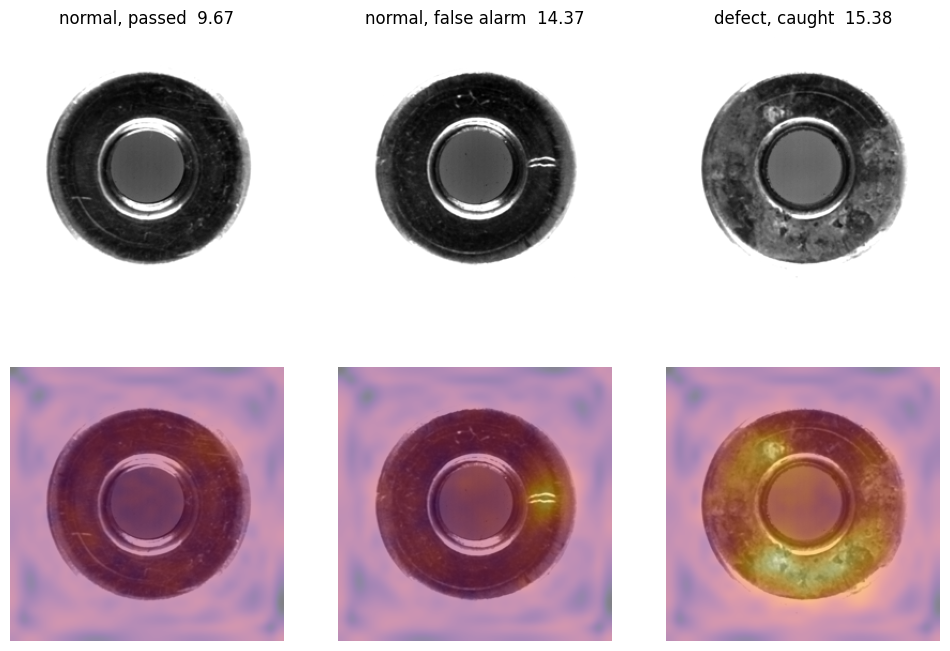

In [19]:
%matplotlib inline
vmin = float("inf")
vmax = float("-inf")
for title, path, amap, s in shown:
    vmin = min(vmin, amap.min())
    vmax = max(vmax, amap.max())

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for col, (title, path, amap, s) in enumerate(shown):
    gray = Image.open(path).resize(amap.shape[::-1])
    axes[0, col].imshow(gray, cmap="gray")
    axes[0, col].set_title(f"{title}  {s:.2f}")
    axes[1, col].imshow(gray, cmap="gray")
    axes[1, col].imshow(amap, cmap="inferno", alpha=0.5, vmin=vmin, vmax=vmax)

for ax in axes.flat:
    ax.axis("off")
    
plt.savefig(RUN_DIR / "heatmaps_B_above.png")
plt.show()